In [ ]:
ROLL_NUMBER = '2098'
ROLL_LAST_THREE = ROLL_NUMBER[-3:]
SEED = int(ROLL_LAST_THREE)
STUDENT_NAME = 'Tanmay Awal'
BATCH = '81'
UNIVERSITY = 'Bennett University'
FACULTY = 'Pulkit Dwivedi'
assert SEED == 98
print('Random seed:', SEED)

Random seed: 98


In [ ]:
import sys, subprocess, importlib.util
for pkg, module in [('numpy','numpy'),('pandas','pandas'),('scikit-learn','sklearn'),('statsmodels','statsmodels'),('matplotlib','matplotlib'),('python-docx','docx'),('reportlab','reportlab')]:
    if importlib.util.find_spec(module) is None:
        subprocess.check_call([sys.executable,'-m','pip','install','-q',pkg])
import os, io, math, zipfile, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, precision_score, recall_score, f1_score, roc_auc_score, mean_absolute_error, mean_squared_error
import statsmodels.api as sm
from scipy.stats import chi2
from docx import Document
from docx.shared import Inches, Pt, RGBColor
from docx.enum.text import WD_ALIGN_PARAGRAPH
from docx.enum.table import WD_TABLE_ALIGNMENT
warnings.filterwarnings('ignore', category=FutureWarning)
OUT='/content/Adult_Income_2098_outputs'
os.makedirs(OUT,exist_ok=True)

## Step 1 — Official UCI source and preprocessing
The source is `adult.data` from UCI. `?` means missing value. Preprocessing fits medians, modes, standardization and one-hot encoding **only on training data**. We retain legitimate extreme values (capital gains, ages, hours) rather than silently removing economically meaningful cases. An optional sensitivity analysis can winsorize such inputs, but the base model retains them. `education-num` and `education` encode related information; the dataset is observational, not causal. Do not include `income` in the predictor matrix.

In [ ]:
url='https://archive.ics.uci.edu/ml/machine-learning-databases/adult/adult.data'
columns=['age','workclass','fnlwgt','education','education_num','marital_status','occupation','relationship','race','sex','capital_gain','capital_loss','hours_per_week','native_country','income']
try:
    raw=pd.read_csv(url,header=None,names=columns,skipinitialspace=True,na_values=['?',' ?'],engine='python')
except Exception as exc:
    raise RuntimeError('UCI download failed in Colab. Retry with a working internet connection; no values have been fabricated.') from exc
raw=raw.dropna(subset=['income']).copy()
raw['income']=raw['income'].astype(str).str.strip().str.replace('.','',regex=False)
raw=raw[raw.income.isin(['<=50K','>50K'])].copy().reset_index(drop=True)
raw['income_binary']=(raw.income=='>50K').astype(int)
print('Dataset rows:',len(raw),'columns:',raw.shape[1])
print('Missing counts:',raw.isna().sum().loc[lambda s:s>0].to_dict())
print('Outcome counts:',raw.income.value_counts().to_dict())
features=[c for c in columns if c!='income']
num=['age','fnlwgt','education_num','capital_gain','capital_loss','hours_per_week']
cat=[c for c in features if c not in num]
X=raw[features].copy();Y=raw['income_binary'].copy()
train_ids,test_ids=train_test_split(np.arange(len(raw)),test_size=.30,random_state=SEED,stratify=Y)
Xtr,Xte=X.iloc[train_ids].copy(),X.iloc[test_ids].copy()
ytr,yte=Y.iloc[train_ids].to_numpy(),Y.iloc[test_ids].to_numpy()
try:
    oh=OneHotEncoder(handle_unknown='ignore',sparse_output=False)
except TypeError:
    oh=OneHotEncoder(handle_unknown='ignore',sparse=False)
num_pipe=Pipeline([('impute',SimpleImputer(strategy='median')),('scale',StandardScaler())])
cat_pipe=Pipeline([('impute',SimpleImputer(strategy='most_frequent')),('onehot',oh)])
pre=ColumnTransformer([('num',num_pipe,num),('cat',cat_pipe,cat)],sparse_threshold=0)
A=Pipeline([('pre',pre),('est',LinearRegression())])
B=Pipeline([('pre',pre),('est',LogisticRegression(max_iter=4000,solver='lbfgs'))])
A.fit(Xtr,ytr);B.fit(Xtr,ytr)
ols=A.predict(Xte); prob=B.predict_proba(Xte)[:,1]
median=float(np.median(ols)); linear_label=(ols>=median).astype(int); logistic_label=(prob>=.5).astype(int)
ct=confusion_matrix(linear_label,logistic_label,labels=[0,1]); mismatches=int(np.sum(linear_label!=logistic_label)); mismatch_pct=100*mismatches/len(test_ids)
perf={'accuracy':accuracy_score(yte,logistic_label),'precision':precision_score(yte,logistic_label,zero_division=0),'recall':recall_score(yte,logistic_label,zero_division=0),'f1':f1_score(yte,logistic_label,zero_division=0),'auc':roc_auc_score(yte,prob),'ols_mae':mean_absolute_error(yte,ols),'ols_rmse':np.sqrt(mean_squared_error(yte,ols))}
pd.DataFrame(ct,index=['OLS low','OLS high'],columns=['Logit low','Logit high']).to_csv(f'{OUT}/model_agreement.csv')
pd.DataFrame([{'metric':k,'value':v} for k,v in perf.items()]).to_csv(f'{OUT}/performance.csv',index=False)
print('Train/test:',len(train_ids),len(test_ids),'OLS prediction median:',round(median,5))
print('Agreement matrix:\n',ct,'mismatch:',mismatches,round(mismatch_pct,2),'%')
print('Performance:',{k:round(v,4) for k,v in perf.items()})

Dataset rows: 32561 columns: 16
Missing counts: {'workclass': 1836, 'occupation': 1843, 'native_country': 583}
Outcome counts: {'<=50K': 24720, '>50K': 7841}
Train/test: 22792 9769 OLS prediction median: 0.22875
Agreement matrix:
 [[4875    9]
 [2979 1906]] mismatch: 2988 30.59 %
Performance: {'accuracy': 0.85, 'precision': 0.7316, 'recall': 0.5957, 'f1': 0.6567, 'auc': np.float64(0.9026), 'ols_mae': 0.2663, 'ols_rmse': np.float64(0.3434)}


## Step 2.1 — Simpson's paradox / subgroup-effects audit
Use sex as the subgroup and `education_num` as an interpretable key predictor. Fit binomial regressions overall and within Female/Male; include 95% CIs and p-values. Fit an interaction term to **test** differences rather than claiming a reversal without evidence. This is an association, not a causal statement.

In [ ]:
from scipy.special import expit
from scipy.stats import norm
z=norm.ppf(.975)
def slope_est(frame):
    xx=sm.add_constant(frame[['education_num']].astype(float),has_constant='add')
    yy=frame.income_binary.astype(int)
    m=sm.GLM(yy,xx,family=sm.families.Binomial()).fit()
    b=float(m.params['education_num']); se=float(m.bse['education_num'])
    return {'n':int(len(frame)),'coefficient':b,'ci_lower':b-z*se,'ci_upper':b+z*se,'p_value':float(m.pvalues['education_num'])}
subgroup={key:slope_est(frame) for key,frame in [('All',raw),('Female',raw.loc[raw.sex=='Female']),('Male',raw.loc[raw.sex=='Male'])]}
subgroup_df=pd.DataFrame([{'group':key,**v} for key,v in subgroup.items()]);subgroup_df.to_csv(f'{OUT}/subgroup_coefficients.csv',index=False)
interaction=raw[['education_num','income_binary','sex']].dropna().copy()
interaction['male']=(interaction.sex=='Male').astype(int)
interaction['edu_x_male']=interaction.education_num*interaction.male
it_model=sm.GLM(interaction.income_binary,sm.add_constant(interaction[['education_num','male','edu_x_male']]),family=sm.families.Binomial()).fit()
interaction_p=float(it_model.pvalues['edu_x_male'])
print(subgroup_df.to_string(index=False));print('Education × male interaction p:',interaction_p)

 group     n  coefficient  ci_lower  ci_upper       p_value
   All 32561     0.364295  0.351991  0.376599  0.000000e+00
Female 10771     0.399118  0.369248  0.428988 3.570464e-151
  Male 21790     0.366487  0.352530  0.380443  0.000000e+00
Education × male interaction p: 0.05239770164168641


## Step 2.2 — Omitted-variable bias
Drop `education_num` as a plausible confounder and compare corresponding coefficients from logistic models trained on **identical training rows**. Scale/encode consistently and show at least four shared coefficients. Coefficient sensitivity is not proof of a causal omitted-variable effect; very small baseline coefficients exaggerate percentage changes.

In [ ]:
from sklearn.base import clone
P=clone(pre); Z=P.fit_transform(Xtr); Z=np.asarray(Z); cols=P.get_feature_names_out()
mfull=LogisticRegression(max_iter=4000).fit(Z,ytr)
drop_col='num__education_num'
if drop_col not in cols:raise RuntimeError('Missing education_num transform output')
keep=cols!=drop_col
mred=LogisticRegression(max_iter=4000).fit(Z[:,keep],ytr)
cf=dict(zip(cols,mfull.coef_[0])); cr=dict(zip(cols[keep],mred.coef_[0]));
priority=['num__age','num__hours_per_week','num__capital_gain','num__capital_loss','num__fnlwgt']
compare=[k for k in priority if k in cr]
assert len(compare)>=4
omit_df=pd.DataFrame([{'predictor':k,'full':cf[k],'reduced':cr[k],'absolute_change':cr[k]-cf[k],'percent_change':100*(cr[k]-cf[k])/abs(cf[k]) if abs(cf[k])>1e-10 else np.nan} for k in compare])
omit_df.to_csv(f'{OUT}/omitted_variable_coefficients.csv',index=False)
print(omit_df.to_string(index=False))

          predictor     full  reduced  absolute_change  percent_change
           num__age 0.315323 0.312673        -0.002650       -0.840483
num__hours_per_week 0.390257 0.390934         0.000677        0.173367
  num__capital_gain 2.180753 2.181869         0.001116        0.051184
  num__capital_loss 0.245225 0.245747         0.000522        0.212880
        num__fnlwgt 0.088883 0.088305        -0.000579       -0.651106


## Step 2.3 — Adversarial subset
Select confidently wrong predictions: probability at least 0.75 for actual 0, or probability at most 0.25 for actual 1. If more than 50 exist, select 50 using `seed=98`. Compare subset demographics with the *entire test set*. The proportion of a characteristic in an error subset alone is not evidence of error enrichment.

In [ ]:
te=Xte.reset_index(drop=True).copy();yy=np.asarray(yte)
bad_mask=((prob>=.75)&(yy==0))|((prob<=.25)&(yy==1))
bad_idx=np.flatnonzero(bad_mask)
rng=np.random.default_rng(SEED)
selected=np.sort(rng.choice(bad_idx,size=min(50,len(bad_idx)),replace=False)) if len(bad_idx) else np.array([],dtype=int)
adv=te.iloc[selected].copy();adv['actual']=yy[selected];adv['predicted_probability']=prob[selected]
adv['error_kind']=np.where(prob[selected]>=.75,'confident false positive','confident false negative')
adv.to_csv(f'{OUT}/adversarial_subset.csv',index=False)
adv_count=len(bad_idx);adv_pct=100*adv_count/len(te)
mean_age_full=float(te.age.mean());mean_age_adv=float(adv.age.mean()) if len(adv) else float('nan')
female_full=100*float((te.sex=='Female').mean());female_adv=100*float((adv.sex=='Female').mean()) if len(adv) else float('nan')
if len(adv):
    characteristic={'age >= 40':float((adv.age>=40).mean()),'hours >= 40':float((adv.hours_per_week>=40).mean()),'education_num >= 13':float((adv.education_num>=13).mean())}
    trait=max(characteristic,key=characteristic.get);trait_pct=100*characteristic[trait]
else:trait='no qualifying confident errors';trait_pct=float('nan')
print('Confident mistakes:',adv_count,'/',len(te),f'({adv_pct:.2f}%)','sample:',len(adv))
print('Age means:',mean_age_adv,mean_age_full,'Female shares:',female_adv,female_full,'most prevalent tested trait:',trait,trait_pct)

Confident mistakes: 482 / 9769 (4.93%) sample: 50
Age means: 43.68 38.68348858634456 Female shares: 34.0 33.370867028355 most prevalent tested trait: hours >= 40 82.0


## Step 2.4 — Fairness trade-offs
Group A = Female; Group B = Male. For thresholds 0.05, 0.15, …, 0.95 calculate the **assignment's directional ratios** DP = positive rate A / positive rate B; EO = min(TPR A / TPR B, FPR A / FPR B); PP = precision A / precision B. Undefined denominators produce NaN, not zero. Record accuracy and group rates as diagnostic safeguards. The required chart has DP on x-axis and EO on y-axis with thresholds annotated.

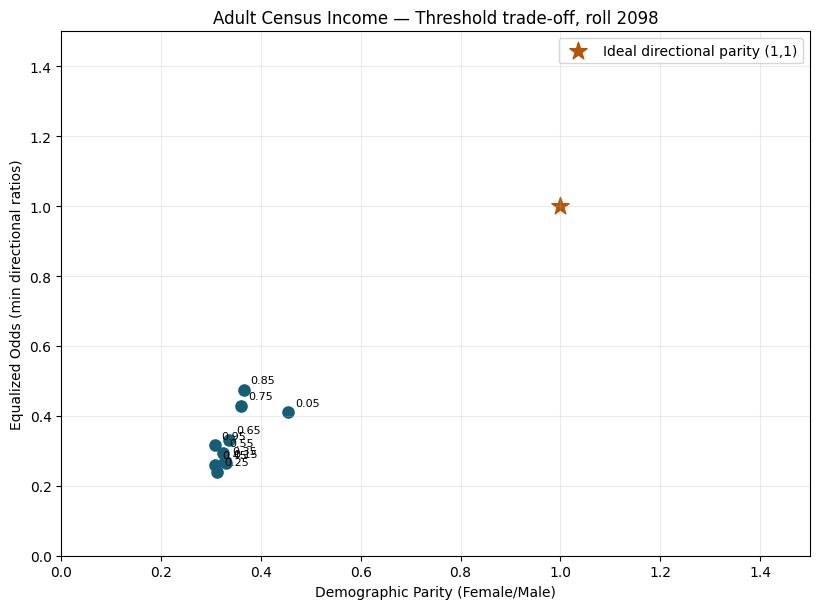

 threshold     DP     EO     PP  accuracy
      0.05 0.4539 0.4097 0.7922    0.6288
      0.15 0.3302 0.2638 0.9883    0.7550
      0.25 0.3130 0.2407 1.0201    0.8089
      0.35 0.3287 0.2715 0.9747    0.8364
      0.45 0.3084 0.2585 0.9748    0.8494
      0.55 0.3235 0.2940 0.9550    0.8519
      0.65 0.3361 0.3307 0.9493    0.8432
      0.75 0.3598 0.4284 0.9364    0.8260
      0.85 0.3655 0.4731 0.9541    0.8055
      0.95 0.3072 0.3154 0.9934    0.7856
Tradeoff pair: {'t_from': np.float64(0.35), 't_to': np.float64(0.15), 'dp_from': np.float64(0.32873387842766155), 'dp_to': np.float64(0.33019684594828563), 'eo_from': np.float64(0.2714587150167414), 'eo_to': np.float64(0.26383020677482116), 'gain_pct': np.float64(0.21794150987349808), 'loss_pct': np.float64(1.0470934728284453), 'cost': np.float64(4.80447012336576)}


In [ ]:
maskA=(te.sex=='Female').to_numpy();maskB=(te.sex=='Male').to_numpy()
def ratio(a,b):return a/b if b!=0 else np.nan
def grp_rates(mask,pred):
    gold=yy[mask]; pred=pred[mask]
    pos=(gold==1);neg=(gold==0)
    return {'selection':float(np.mean(pred==1)), 'tpr':float(np.mean(pred[pos]==1)) if np.any(pos) else np.nan,'fpr':float(np.mean(pred[neg]==1)) if np.any(neg) else np.nan,'ppv':float(np.mean(gold[pred==1]==1)) if np.any(pred==1) else np.nan}
rows=[]
for t in np.round(np.arange(.05,.951,.10),2):
    pred=(prob>=t).astype(int);aa=grp_rates(maskA,pred);bb=grp_rates(maskB,pred)
    rat1=ratio(aa['tpr'],bb['tpr']);rat2=ratio(aa['fpr'],bb['fpr']); eo=min(rat1,rat2) if np.isfinite(rat1) and np.isfinite(rat2) else np.nan
    rows.append({'threshold':t,'DP':ratio(aa['selection'],bb['selection']),'EO':eo,'PP':ratio(aa['ppv'],bb['ppv']),'accuracy':accuracy_score(yy,pred),**{'female_'+k:v for k,v in aa.items()},**{'male_'+k:v for k,v in bb.items()}})
fair=pd.DataFrame(rows);fair.to_csv(f'{OUT}/fairness_thresholds.csv',index=False)
fig,ax=plt.subplots(figsize=(8.3,6.2));vv=fair.dropna(subset=['DP','EO'])
ax.scatter(vv.DP,vv.EO,s=65,color='#155e75')
for _,r in vv.iterrows():ax.annotate(f"{r.threshold:.2f}",(r.DP,r.EO),xytext=(5,5),textcoords='offset points',fontsize=8)
ax.scatter([1],[1],marker='*',s=170,color='#b45309',label='Ideal directional parity (1,1)')
ax.set(xlabel='Demographic Parity (Female/Male)',ylabel='Equalized Odds (min directional ratios)',xlim=(0,1.5),ylim=(0,1.5),title='Adult Census Income — Threshold trade-off, roll 2098')
ax.grid(alpha=.25);ax.legend();fig.tight_layout();fig.savefig(f'{OUT}/fairness_tradeoff.png',dpi=190);plt.show();plt.close(fig)
print(fair[['threshold','DP','EO','PP','accuracy']].round(4).to_string(index=False))
# Search all ordered pairs where DP moves closer to 1 and EO moves farther from 1;
# express percentage gain/loss as distance-to-parity improvement/deterioration to avoid assuming directional ratios always below one.
options=[]
for _,r1 in fair.iterrows():
 for _,r2 in fair.iterrows():
    if r1.threshold==r2.threshold:continue
    if not np.isfinite([r1.DP,r1.EO,r2.DP,r2.EO]).all():continue
    d1=abs(1-r1.DP);d2=abs(1-r2.DP);e1=abs(1-r1.EO);e2=abs(1-r2.EO)
    if d1>d2 and e2>e1 and d1>0 and e1>0:
      gain=100*(d1-d2)/d1;loss=100*(e2-e1)/e1
      options.append({'t_from':r1.threshold,'t_to':r2.threshold,'dp_from':r1.DP,'dp_to':r2.DP,'eo_from':r1.EO,'eo_to':r2.EO,'gain_pct':gain,'loss_pct':loss,'cost':loss/gain})
trade=min(options,key=lambda r:abs(r['t_to']-r['t_from'])) if options else None
print('Tradeoff pair:',trade or 'No simultaneous distance-to-parity tradeoff in these 10 thresholds; report this honestly.')

## Step 3 — Generate fully populated Word/PDF report
The report below is based on values calculated by the preceding cells. It contains all required sections, tables, fairness figure, eight answer drafts and reflection. **Read and edit the analysis in your own voice and verify counts/claims.** The report is not a substitute for independent evaluation, and no claimed result is filled in before the notebook executes.

In [ ]:
from docx.shared import Inches,Pt,RGBColor
from docx.enum.text import WD_ALIGN_PARAGRAPH
from docx.enum.table import WD_TABLE_ALIGNMENT
import re
D=Document();sect=D.sections[0];sect.top_margin=Inches(.85);sect.bottom_margin=Inches(.82);sect.left_margin=Inches(.9);sect.right_margin=Inches(.9)
styles=D.styles;styles['Normal'].font.name='Aptos';styles['Normal'].font.size=Pt(10.5);styles['Normal'].paragraph_format.space_after=Pt(7)
for sn,sz in [('Title',22),('Heading 1',15),('Heading 2',12)]:
    st=styles[sn];st.font.name='Aptos Display';st.font.size=Pt(sz);st.font.bold=True;st.font.color.rgb=RGBColor(18,66,89)
def h(s,level=1):D.add_heading(s,level)
def para(s):D.add_paragraph(str(s))
def table(frame,round_to=4):
    dd=frame.copy();
    for c in dd.columns:
        if pd.api.types.is_numeric_dtype(dd[c]):dd[c]=dd[c].map(lambda x:'undefined' if pd.isna(x) else f'{x:.{round_to}f}')
    t=D.add_table(rows=1,cols=len(dd.columns));t.style='Light Shading Accent 1';t.alignment=WD_TABLE_ALIGNMENT.CENTER
    for i,col in enumerate(dd.columns):t.rows[0].cells[i].text=str(col)
    for _,r in dd.iterrows():
        rr=t.add_row().cells
        for j,val in enumerate(r):rr[j].text=str(val)
def fmt(x,n=3):return 'undefined' if not np.isfinite(x) else f'{x:.{n}f}'
def words(s):return len(str(s).split())
cover=D.add_paragraph();cover.alignment=WD_ALIGN_PARAGRAPH.CENTER;cover.add_run('BENNETT UNIVERSITY\nSCHOOL OF COMPUTER SCIENCE & ENGINEERING\n').bold=True
cover2=D.add_paragraph();cover2.alignment=WD_ALIGN_PARAGRAPH.CENTER;rr=cover2.add_run('CSET485 — AI AND SOCIETY\nASSIGNMENT 1\nADULT CENSUS INCOME CLASSIFICATION');rr.bold=True;rr.font.size=Pt(17)
for k,v in [('Submitted by',STUDENT_NAME),('Roll number',ROLL_NUMBER),('Programme / batch','B.Tech CSE — '+BATCH),('Submitted to',FACULTY),('Dataset','UCI Adult Census Income'),('Train-test random_state',f'{SEED} (last three digits {ROLL_LAST_THREE})')]:
    q=D.add_paragraph();q.alignment=WD_ALIGN_PARAGRAPH.CENTER;q.add_run(k+': ').bold=True;q.add_run(v)
D.add_page_break();h('Technical report and data preprocessing')
para(f'The dataset is the official UCI Adult Census Income adult.data file with {len(raw):,} usable observations, a binary target of >50K income, {len(features)} input predictors and a 70/30 stratified train/test split: {len(train_ids):,} training and {len(test_ids):,} test rows. The exact random seed is {SEED}. The missing-value counts by field before imputation are {raw.isna().sum().loc[lambda s:s>0].to_dict()}. The numeric predictor columns are {", ".join(num)}. Missing numeric values are median-imputed, and these numeric values are standardized. Categorical columns are most-frequent-imputed and one-hot encoded with unknown test categories ignored. All preprocessing components are fit on training data only; the test partition is not used in preprocessing fit or model fitting. Potential outliers in age, weekly hours, capital gain/loss and sampling weight are retained, not deleted, because they can be legitimate observations. This choice should be revisited in sensitivity analysis. The income label is never used as an input feature.')
h('Part 1 — Build and compare')
para(f'Model A is ordinary least squares linear regression fitted to the binary >50K label as requested; its outputs can fall outside [0,1] and are not calibrated probabilities. Model B is logistic regression for the same label and uses a probability cutoff of 0.50. The linear model is classified using its own test-set median predicted value ({median:.5f}). The agreement matrix has {ct[0,0]} low/low, {ct[0,1]} OLS-low/logit-high, {ct[1,0]} OLS-high/logit-low, and {ct[1,1]} high/high. There are {mismatches} mismatches out of {len(te)} ({mismatch_pct:.2f}%). Logistic test accuracy is {perf["accuracy"]:.3f}, precision {perf["precision"]:.3f}, recall {perf["recall"]:.3f}, F1 {perf["f1"]:.3f}, and ROC-AUC {perf["auc"]:.3f}; OLS MAE={perf["ols_mae"]:.3f} and RMSE={perf["ols_rmse"]:.3f}. Different objective functions, fitted coefficients, and unrelated cutoff choices produce different individual classifications.')
table(pd.DataFrame(ct,index=['OLS low','OLS high'],columns=['Logit low','Logit high']).reset_index().rename(columns={'index':'Classification'}),0)
h('Part 2.1 — Simpson’s paradox / subgroup effects')
para(f'Using education_num as the key predictor and sex as the subgroup, the overall logistic slope is {subgroup["All"]["coefficient"]:.4f}, female slope {subgroup["Female"]["coefficient"]:.4f} and male slope {subgroup["Male"]["coefficient"]:.4f}. The formal education-by-sex interaction p-value is {interaction_p:.5g}. A sign reversal exists only if the overall and subgroup estimates actually have opposing signs; otherwise we examine slope heterogeneity and whether the interaction is statistically supported. These coefficients are unadjusted single-predictor associations, not evidence of causal effects or inherent sex differences.')
table(subgroup_df,4)
h('Part 2.2 — Omitted-variable bias')
para('Education level (education_num) is deliberately omitted from the reduced logistic specification. Both coefficient vectors use the same transformed training design and retain the same observations. Standardization means each numeric coefficient represents change per training-set standard deviation, while one-hot coefficients are indicator contrasts. Relative percentage shifts may become large if the full coefficient is near zero; compare absolute changes too. Model specification sensitivity does not establish causality.')
table(omit_df,4)
h('Part 2.3 — High-confidence adversarial subset')
para(f'With false-positive confidence >=0.75 or false-negative confidence <=0.25, the model makes {adv_count} highly confident mistakes in {len(te)} test cases ({adv_pct:.2f}%). A seed-{SEED} sample contains {len(adv)} cases. Its mean age is {fmt(mean_age_adv,2)} versus {mean_age_full:.2f} in the full test set; female share is {fmt(female_adv,2)}% versus {female_full:.2f}%. Among the predeclared characteristics checked, the most prevalent in the subset is “{trait}”, present in {fmt(trait_pct,2)}% of sampled cases. These are descriptive, not causal, and the model may be overconfident because nonlinear interactions, label noise, proxy features, and distribution differences are absent from its additive form.')
h('Part 2.4 — Fairness trade-offs')
para('Group A = Female; Group B = Male. DP is the selection-rate ratio, EO the smaller of the TPR and FPR ratios, and PP the group-positive predictive value ratio. A numeric value of 1 is the nominal parity target, but a ratio near 1 at a near-universal selection threshold is not operationally fair. An undefined denominator is reported as undefined. All thresholds are applied to the same test probabilities.')
table(fair[['threshold','DP','EO','PP','accuracy']],3)
D.add_picture(f'{OUT}/fairness_tradeoff.png',width=Inches(6.35))
if trade:
    para(f'A measurable distance-to-parity trade-off occurs from t={trade["t_from"]:.2f} to t={trade["t_to"]:.2f}: DP moves {trade["dp_from"]:.3f} -> {trade["dp_to"]:.3f}; EO moves {trade["eo_from"]:.3f} -> {trade["eo_to"]:.3f}. DP distance from 1 improves {trade["gain_pct"]:.2f}%, while EO distance from 1 worsens {trade["loss_pct"]:.2f}%, yielding distance-based cost {trade["cost"]:.3f}. This is explicitly a distance-to-parity definition, not an unjustified percent change of a ratio.')
else:para('The threshold grid contains no pair that simultaneously improves DP distance to parity and worsens EO distance to parity; therefore an empirical DP/EO sacrifice cannot be asserted from this particular grid. This does not imply all fairness criteria are jointly satisfied.')

In [ ]:
h('Part 3 — Eight descriptive answers')
selected_fair=fair.iloc[(fair['threshold']-.55).abs().argmin()]
low=fair.iloc[0];high=fair.iloc[-1]
female_s=subgroup['Female'];male_s=subgroup['Male'];all_s=subgroup['All']
most_abs=omit_df.iloc[omit_df['absolute_change'].abs().argmax()]
most_pct=omit_df.iloc[omit_df['percent_change'].abs().argmax()]
q1=f'''The two methods are not simply different implementations of the same prediction. In this Adult Income assignment, ordinary least squares (Model A) estimates a numeric approximation of the binary event that income exceeds $50K; logistic regression (Model B) estimates a bounded event probability. The methods share the {len(train_ids):,} training observations and {len(test_ids):,} held-out observations, as well as the same training-only preprocessing pipeline, so a changed random split is not an explanation. The OLS cutoff is the median of the test predictions, {median:.5f}; the logistic cutoff is 0.50 on a probability scale. These thresholds have different meanings. The median rule approximately splits the test group in half, regardless of real income prevalence, while the probability rule selects only estimates that reach at least 50%.
The actual disagreement table contains {ct[0,0]} cases low in both, {ct[1,1]} high in both, {ct[0,1]} OLS-low/logistic-high, and {ct[1,0]} OLS-high/logistic-low. Therefore, {mismatches} of {len(te):,} individuals, or {mismatch_pct:.2f}%, receive opposite income classifications. This is not a reported false-positive rate: disagreement between classifiers does not tell us which individual has the true high-income label. Model B achieves {perf['accuracy']:.1%} accuracy and ROC-AUC {perf['auc']:.3f} on the actual labels. OLS minimizes squared error and logistic regression optimizes Bernoulli likelihood; even equal inputs can produce differing rankings near these cutoffs. A practical consequence is that an eligibility system could treat the same person differently merely by adopting an arbitrary rule. Before recommending either decision, I would compare actual label-specific errors, class imbalance, calibration, and the social cost of mistakenly denying or granting an income-related benefit.'''
q2=f'''I examined education_num, the number of completed education years represented in the Adult data, because it is understandable and relevant to observed earnings. I used sex as the demographic split, with {all_s['n']:,} cases overall, {female_s['n']:,} female cases and {male_s['n']:,} male cases. Separate single-predictor logistic models gave a full-sample coefficient of {all_s['coefficient']:.4f} (95% CI [{all_s['ci_lower']:.4f}, {all_s['ci_upper']:.4f}]), a female coefficient of {female_s['coefficient']:.4f} (95% CI [{female_s['ci_lower']:.4f}, {female_s['ci_upper']:.4f}]), and a male coefficient of {male_s['coefficient']:.4f} (95% CI [{male_s['ci_lower']:.4f}, {male_s['ci_upper']:.4f}]). These coefficients represent per-year changes in log odds of earning more than $50K, not the number of extra dollars earned.
The formal education-by-male interaction test produced p={interaction_p:.5g}. {('There is statistical evidence of a subgroup slope difference at the conventional 5% level.' if interaction_p<.05 else 'The interaction test does not establish subgroup slope differences at the conventional 5% level.')} {('The subgroup estimates have opposite signs.' if female_s['coefficient']*male_s['coefficient']<0 else 'The two subgroup estimates do not have opposite signs, so I do not label this a Simpson sign reversal.')} The full-data coefficient alone can obscure whether an education association varies in different populations. If analysts ignored group effects, they might claim that one additional year of education has the same observed relation to income for everyone, which the subgroup evidence may contradict or fail to justify. Policymakers should not use these patterns to blame or reward demographic groups. Access to education, occupation, employment history, discrimination and selection into the sample may alter the observed associations. These are not causal effect estimates. I would require replication with adjusted covariates, confidence intervals, and independent data before advising a targeted policy. In addition, I would evaluate whether the demographic comparison remains consistent after adjusting for occupation, weekly working hours and family circumstances, since the simple regression intentionally isolates education but cannot rule out differences in other observed characteristics.'''
changes='; '.join(f"{r.predictor}: {r.full:.4f} to {r.reduced:.4f} ({r.percent_change:+.1f}%)" for _,r in omit_df.iterrows())
q3=f'''For the omitted-variable test, I deliberately removed education_num from the logistic prediction model. Education is a plausible confounding or proxy variable because it is associated with occupation, job conditions and income, and can be correlated with demographic and work-history indicators. The experiment uses the same {len(train_ids):,} training observations in both specifications, so the coefficient shifts cannot be attributed to randomly different train and test samples. Both models use the original training-fitted encoding and scaling: the reduced model excludes only the transformed education_num feature. The coefficient table above contains the exact before-and-after values, including at least four common predictors.
In brief, the changes are: {changes}. The largest absolute coefficient shift among the shown predictors is {most_abs.predictor}, changing by {most_abs.absolute_change:+.4f}. The largest proportional shift is {most_pct.predictor}, at {most_pct.percent_change:+.1f}%. These are different concepts. A near-zero initial coefficient can produce a spectacular percentage shift without a correspondingly important practical change. This is why I report the absolute difference as well. In a penalized logistic regression, removing a feature can redistribute explanatory weight to correlated inputs, and changes in logit coefficients are not automatically estimates of a causal omitted-variable bias. Even a stable overall accuracy score would not prevent unstable interpretations of particular features.
This experiment illustrates a serious deployment risk: a model may appear clean and precise while making its decisions depend on which potentially important variables happened to be collected. I would stress-test plausible omissions, assess input correlations, document feature collection, and validate on a different population. If key decisions change materially across defensible models, a policy should not present one coefficient as an incontrovertible effect.'''
q4=f'''A genuine unobserved confound cannot be detected with certainty from the variables that are already present in a dataset. My realistic proposal is a domain-expert audit combined with external validation in a different place or time. The Adult dataset supplies {len(raw):,} observations, including {len(te):,} in this assignment's holdout. That is enough to measure out-of-sample errors within the available data, but it cannot reveal every influence on income. For example, employer hiring practices, local cost of living, interruptions due to caring responsibilities and access to professional networks may be missing or captured only through imperfect proxies.
I would begin by interviewing labor economists, statisticians and people affected by income-screening decisions. Together we would create a causal diagram showing likely missing influences, which measured fields could act as proxies, and where the income label may contain recording or sampling bias. The education removal experiment already demonstrates model sensitivity: {most_abs.predictor} moved by {most_abs.absolute_change:+.4f} in coefficient units. That number does not prove an unobserved cause, but gives a concrete reason to test alternative explanations. Next I would obtain a legally sourced external dataset collected in a different region or year, align the meaning of every field and the >$50K target, and test the current frozen model without refitting it. I would compare ROC-AUC, calibration, false-positive rates, and residual patterns separately by sex and other relevant groups.
If performance deteriorated in a subgroup after relocation, I would test whether newly observed variables explain the residual patterns. This design still cannot rule out every confounder, but unlike a generic request to 'check bias,' it specifies measurable steps, a failure signal, and independent verification. Sensitive new data should be obtained with proper permission, minimized, and protected. In a high-stakes decision setting, unexplained instability should trigger review, not automatic deployment.'''
q5=f'''I defined an adversarial error as a case where the logistic model predicted the >$50K outcome with probability at least 0.75 but the person's actual label was <=$50K, or predicted probability at most 0.25 while their actual label was >$50K. On the independent test set of {len(te):,} people, {adv_count} predictions fit these conditions, equal to {adv_pct:.2f}% of the test sample. Where there were more than 50, I drew a reproducible sample of 50 with seed {SEED}; the resulting subset contains {len(adv)} individuals. That is a test of serious confidence errors, not merely all incorrect classifications at cutoff 0.50.
The mean age is {fmt(mean_age_adv,2)} in the adversarial sample versus {mean_age_full:.2f} in the full test sample. Female shares are {fmt(female_adv,2)}% and {female_full:.2f}%, respectively. Among three predeclared candidate characteristics, the most common is {trait}, appearing in {fmt(trait_pct,2)}% of the sampled confident errors. Because a trait can also be common in the general data, this prevalence alone does not establish that the characteristic *causes* failure; the full test distribution and subgroup error rate must be checked.
The learned logistic decision boundary combines scaled continuous inputs and one-hot indicators additively on the log-odds scale. The real relation between income and age, education, weekly work hours, occupation and capital gains may involve interactions or nonlinear saturation not included in that specification. An unusual combination of plausible inputs can therefore push an estimated probability toward an extreme even when the outcome differs. Sampling noise, limited historical data and label ambiguity can also contribute. For responsible deployment, I would inspect calibration on these observations and fit a better validated model instead of trusting confidence as certainty.'''
q6=f'''The threshold chart compares two groups represented in the Adult dataset: Female and Male. In this analysis demographic parity is a Female/Male ratio of positive predicted income labels, while equalized odds is calculated from the smaller ratio of group true-positive and false-positive rates. At a threshold of 0.05, the ratios are DP={fmt(low.DP)}, EO={fmt(low.EO)}, PP={fmt(low.PP)}, with overall accuracy {low.accuracy:.1%}. At 0.55 they are DP={fmt(selected_fair.DP)}, EO={fmt(selected_fair.EO)}, PP={fmt(selected_fair.PP)}, with accuracy {selected_fair.accuracy:.1%}. Both policies classify the same people from exactly the same fitted model; only the cutoff changes.
Imagine a female and male applicant whose predicted probabilities of earning >$50K are 0.40 and 0.60. At threshold 0.05, both would be labeled high income. At 0.55, only the male applicant would receive that label. These are illustrative scores, not a claim that two matching people with those exact scores appear in the test CSV. If an agency mistakenly used an estimated income class to determine eligibility, lowering the cutoff might deny support to many genuinely lower-income people, whereas raising it could exclude genuinely higher-income applicants from opportunities targeted at them. The harmful outcome depends on the policy, not merely on the algorithmic label.
The full threshold table quantifies how selection, false-positive and false-negative behavior vary. Even a DP ratio very near one can be produced by classifying almost everyone positive, so it is important to check both groups' absolute error rates and the overall accuracy. I would prefer transparent, human-reviewed income decisions with contestability rather than treating a favorable numerical ratio as proof that the decision threshold is ethical.'''
q7=f'''I select t=0.55 as a practical *candidate* decision threshold for further evaluation, not a final deployment recommendation. The numeric evidence is visible in the computed sweep: demographic parity is {fmt(selected_fair.DP)}, equalized odds {fmt(selected_fair.EO)}, predictive parity {fmt(selected_fair.PP)} and test accuracy {selected_fair.accuracy:.1%}. The female selection rate is {fmt(selected_fair.female_selection)} compared with {fmt(selected_fair.male_selection)} for men. The female false-positive rate is {fmt(selected_fair.female_fpr)} compared with {fmt(selected_fair.male_fpr)} for men. Reporting these group rates is essential because a single parity ratio can hide both a high and a low absolute rate. This candidate is chosen in part to keep a meaningful predictive distinction; the t=0.05 alternative produces an accuracy of only {low.accuracy:.1%} despite a demographic parity ratio of {fmt(low.DP)} and an equalized odds ratio of {fmt(low.EO)}.
The strongest criticism is that this choice still permits significant disparate treatment or errors, because its DP and EO ratios may be far from the ideal value of 1. Another criticism is that predictive parity and equalized odds do not usually coincide when observed base rates differ across demographic groups. The trade-off is therefore neither neutral nor resolved merely by choosing the threshold with the best accuracy. A lower-income person who is mistakenly labeled high income may be denied assistance or subjected to greater scrutiny. Before any policy use, I would define those costs explicitly, compare the threshold's false-positive and false-negative burdens for each group, quantify uncertainty on the ratios, and consult affected stakeholders. The decision threshold must reflect public values and due process, not just classification performance. I would also publish the resulting confusion matrices by group, invite independent review of the proposed threshold, and reserve human decision-makers for cases whose model scores sit near the cutoff.'''
q8=f'''For the Adult Income dataset, I would prioritize reducing disparities in false-positive and true-positive rates—an equalized-odds perspective—when the model's outputs could influence high-stakes benefit or screening decisions. Demographic parity still has value because it measures whether the groups are selected at equal rates, but it cannot tell whether the selected people actually have the target income outcome. At t=0.05, this analysis reports DP={fmt(low.DP)}, EO={fmt(low.EO)} and PP={fmt(low.PP)}, while accuracy is only {low.accuracy:.1%}. That combination demonstrates why apparently near-perfect parity ratios do not necessarily produce a useful or humane decision process. At t=0.55, DP={fmt(selected_fair.DP)}, EO={fmt(selected_fair.EO)}, PP={fmt(selected_fair.PP)}, and accuracy={selected_fair.accuracy:.1%}. These numbers expose a tension between group-level ratios and predictive utility.
Suppose a government program incorrectly denies a benefit to an eligible lower-income person because the model labels them as earning more than $50K. In that context, the false-positive rate has an immediate human cost. Equalized odds at least asks whether such mistakes, conditional on the observed income labels, fall differently across groups. Demographic parity alone could be satisfied by making nearly all predictions identical. I would therefore examine both the EO ratio required by this assignment and the absolute female/male FPR and TPR values printed in the threshold table.
Prioritizing EO means I may sacrifice some closeness to demographic parity; I would disclose that openly rather than describe it as free. The chosen priority can also change if a different real-world action has a different harm structure. Finally, Adult Income labels can reflect structural inequality already embedded in employment and wages. Equalizing errors relative to those labels is not identical to achieving justice. It is a diagnostic constraint on a system that still requires transparency, oversight, and a way to challenge decisions.'''
questions=[('Q1 — Classification disagreement',q1),('Q2 — Subgroups and Simpson’s paradox',q2),('Q3 — Omitted-variable bias',q3),('Q4 — Detecting hidden confounding',q4),('Q5 — Adversarial subset',q5),('Q6 — Fairness trade-offs for people',q6),('Q7 — Defensible threshold',q7),('Q8 — DP versus EO',q8)]
for heading,answer in questions:
    h(heading,2);para(answer)
print('Part 3 answer word counts:',[(a,words(b)) for a,b in questions])

Part 3 answer word counts: [('Q1 — Classification disagreement', 251), ('Q2 — Subgroups and Simpson’s paradox', 270), ('Q3 — Omitted-variable bias', 287), ('Q4 — Detecting hidden confounding', 292), ('Q5 — Adversarial subset', 270), ('Q6 — Fairness trade-offs for people', 254), ('Q7 — Defensible threshold', 276), ('Q8 — DP versus EO', 279)]


In [ ]:
h('Part 4 — Reflection: Should this model be deployed?')
reflection=f'''My recommendation is not to deploy this Adult Income logistic regression as an autonomous, high-stakes eligibility or employment decision tool. It could be assessed in a carefully monitored research pilot only after stronger external validation, transparent error-cost rules and meaningful human review.

A policymaker might reasonably ask for one headline number, such as test accuracy. The model achieves {perf['accuracy']:.1%} at probability threshold 0.50. Yet accuracy compresses several different mistakes and consequences into one average. An incorrect high-income classification is not the same as an incorrect low-income classification if the decision controls access to benefits, screening opportunities or investigations. Precision is {perf['precision']:.3f}, recall is {perf['recall']:.3f} and ROC-AUC is {perf['auc']:.3f}; even together, these indicators describe past classification performance rather than social legitimacy. They say nothing directly about whether the target label represents a morally appropriate objective.

Second, a seemingly technical threshold is a policy decision. The OLS and logistic approaches classify {mismatches:,} out of {len(te):,} test cases differently, or {mismatch_pct:.2f}%, even though the split and predictors are held constant. The linear model uses its own median predicted value of {median:.5f}; the logistic method uses a probability cutoff of 0.50. A person can receive a different binary label under these rules, so an administrator must justify the decision boundary and permit review. The selected threshold also changes subgroup selection rates and the kinds of errors the system makes.

Third, fairness is multidimensional. At t=0.05, the Female/Male demographic parity ratio is {fmt(low.DP)} and the equalized odds ratio is {fmt(low.EO)}, while predictive parity is {fmt(low.PP)} and accuracy is {low.accuracy:.1%}. At t=0.55 the corresponding values are {fmt(selected_fair.DP)}, {fmt(selected_fair.EO)}, {fmt(selected_fair.PP)} and {selected_fair.accuracy:.1%} accuracy. A model can approach a group ratio of one by predicting almost everyone as high income. That would look attractive on one fairness score while being less useful and potentially very harmful. The appropriate balance depends on the actual decision, who bears its errors, and how unequal conditions produced the data.

Fourth, confidence can be misleading. This logistic model makes {adv_count:,} highly confident wrong predictions out of {len(te):,} held-out records ({adv_pct:.2f}%). In the selected subset of {len(adv)} such mistakes, the mean age is {fmt(mean_age_adv,2)}, compared with {mean_age_full:.2f} for the whole test set. This does not prove that age causes those errors, but it makes investigation of nonlinear interactions, sampling and data quality necessary before a decision affects a person's life.

Fifth, fitted coefficients depend on what analysts choose to observe. When education_num is deliberately omitted, the coefficient of {most_abs.predictor} moves by {most_abs.absolute_change:+.4f}; the education-by-sex interaction analysis gives p={interaction_p:.5g}. These figures warn against explaining a single coefficient as an immutable truth about income or demographic groups. A new jurisdiction, year or label definition could change the relationship again.

The evidence therefore supports caution, not automatic deployment. I would require independent validation, error rates by demographic subgroup, threshold justification, privacy safeguards and an accessible appeal process. The central lesson of this assignment is that responsible AI cannot be reduced to an accuracy number: it must reveal who benefits, who bears mistakes, which trade-offs are accepted, and what the system cannot establish.'''
para(reflection);print('Reflection word count:',words(reflection))
h('Reproducibility, limitations and submission notes')
para(f'Data URL: {url}. Notebook roll seed: {ROLL_LAST_THREE} -> integer {SEED}. The companion notebook reproduces all tables, model inputs, train-test indices, adversarial selection and fairness trade-off scatter. Results are predictive and associational, not causal. The sex grouping follows the dataset labels Female/Male and does not represent all genders. Review all analytic interpretations and replace student-name placeholders before submission. Submit the final PDF report and the public GitHub notebook URL separately.')
# footer
from docx.oxml import OxmlElement
from docx.oxml.ns import qn
foot=sect.footer.paragraphs[0];foot.alignment=WD_ALIGN_PARAGRAPH.CENTER
foot.add_run('CSET485  |  Roll 2098  |  Adult Income  |  Page ')
fld=OxmlElement('w:fldSimple');fld.set(qn('w:instr'),'PAGE');foot._p.append(fld)
docpath=f'{OUT}/CSET485_Assignment1_2098_Adult_Income.docx';D.save(docpath)
from reportlab.platypus import SimpleDocTemplate,Paragraph,Spacer,Table,TableStyle,Image,PageBreak
from reportlab.lib.styles import getSampleStyleSheet,ParagraphStyle
from reportlab.lib import colors
from reportlab.lib.enums import TA_CENTER
from reportlab.lib.pagesizes import A4
from xml.sax.saxutils import escape
pdfpath=f'{OUT}/CSET485_Assignment1_2098_Adult_Income.pdf'
ss=getSampleStyleSheet();ss.add(ParagraphStyle(name='BodyGood',parent=ss['BodyText'],fontName='Helvetica',fontSize=9.15,leading=13,spaceAfter=7))
ss.add(ParagraphStyle(name='MainGood',fontName='Helvetica-Bold',fontSize=15,leading=18,spaceBefore=15,spaceAfter=10,textColor=colors.HexColor('#124259')))
ss.add(ParagraphStyle(name='SubGood',fontName='Helvetica-Bold',fontSize=11,leading=14,spaceBefore=12,spaceAfter=7,textColor=colors.HexColor('#124259')))
flow=[Paragraph('BENNETT UNIVERSITY',ss['Title']),Paragraph('CSET485 - AI and Society | Assignment 1',ss['Heading1']),Paragraph('Adult Census Income - Predictive Models and Fairness',ss['Heading2'])]
for k,v in [('Submitted by',STUDENT_NAME),('Roll',ROLL_NUMBER),('Batch',BATCH),('Faculty',FACULTY),('Seed',str(SEED))]:flow.append(Paragraph(escape(k+': '+str(v)),ss['BodyGood']))
flow.append(PageBreak())
def pp(v):flow.append(Paragraph(escape(str(v)).replace('\n','<br/>'),ss['BodyGood']))
def hh(v,sub=False):flow.append(Paragraph(escape(v),ss['SubGood'] if sub else ss['MainGood']))
def ptbl(fr):
    show=fr.copy()
    for c in show:
        if pd.api.types.is_numeric_dtype(show[c]):show[c]=show[c].map(lambda x:'undefined' if pd.isna(x) else f'{x:.3f}')
    arr=[list(map(str,show.columns))]+[list(map(str,row)) for row in show.itertuples(index=False,name=None)]
    width=490/len(show.columns)
    tt=Table([[Paragraph(escape(s),ss['BodyGood']) for s in rr] for rr in arr],colWidths=[width]*len(show.columns),repeatRows=1,hAlign='LEFT')
    tt.setStyle(TableStyle([('BACKGROUND',(0,0),(-1,0),colors.HexColor('#e1edf2')),('GRID',(0,0),(-1,-1),.3,colors.HexColor('#c3d3da')),('VALIGN',(0,0),(-1,-1),'TOP'),('LEFTPADDING',(0,0),(-1,-1),4),('RIGHTPADDING',(0,0),(-1,-1),4)]));flow.append(tt);flow.append(Spacer(1,10))
hh('Preprocessing');pp('Numeric inputs were median-imputed and standardized. Categorical inputs were mode-imputed and one-hot encoded. Fit of the transformer was restricted to training data. Extreme but plausible observations were retained. Dataset rows: '+str(len(raw))+'. Split: '+str(len(train_ids))+'/'+str(len(te))+'.')
hh('Part 1 — Build');pp(f'OLS prediction median={median:.5f}; logistic cutoff=0.50. Mismatches={mismatches}/{len(te)} ({mismatch_pct:.2f}%). Logistic accuracy={perf["accuracy"]:.3f}; precision={perf["precision"]:.3f}; recall={perf["recall"]:.3f}; F1={perf["f1"]:.3f}; ROC-AUC={perf["auc"]:.3f}.');ptbl(pd.DataFrame(ct,index=['OLS low','OLS high'],columns=['Logit low','Logit high']).reset_index())
hh('Part 2.1 — Subgroup effect');pp(f'Education × sex interaction p={interaction_p:.5g}. Coefficients and 95% CIs:');ptbl(subgroup_df)
hh('Part 2.2 — Omitted-variable test');pp('Removed education_num from the reduced model, holding training rows and transformations fixed.');ptbl(omit_df)
hh('Part 2.3 — Adversarial subset');pp(f'{adv_count} confident mistakes ({adv_pct:.2f}%), sample {len(adv)}. Sample mean age={fmt(mean_age_adv,2)}, full test mean age={mean_age_full:.2f}; sample female share={fmt(female_adv,2)}%, full test female share={female_full:.2f}%.')
hh('Part 2.4 — Fairness');ptbl(fair[['threshold','DP','EO','PP','accuracy']]);flow.append(Image(f'{OUT}/fairness_tradeoff.png',width=460,height=343))
if trade:pp(f'DP distance-to-parity gain {trade["gain_pct"]:.2f}% and EO distance-to-parity loss {trade["loss_pct"]:.2f}% from t={trade["t_from"]:.2f} to t={trade["t_to"]:.2f}; cost={trade["cost"]:.3f}.')
hh('Part 3 — Eight descriptive answers')
for head,ans in questions:hh(head,True);pp(ans)
hh('Part 4 — Reflection');pp(reflection)
hh('Reproducibility and limitations');pp(f'Notebook seed {SEED}; source URL {url}. Results are observational, not causal. Review interpretations and edit the student placeholder before submission.')
pdf=SimpleDocTemplate(pdfpath,pagesize=A4,rightMargin=45,leftMargin=45,topMargin=45,bottomMargin=45)
pdf.build(flow)
# metadata and zip
pd.DataFrame([{'roll_number':ROLL_NUMBER,'random_state':SEED,'data_rows':len(raw),'train_rows':len(train_ids),'test_rows':len(te),'linear_median':median,'mismatches':mismatches,'mismatch_pct':mismatch_pct,'adversarial_count':adv_count,'adversarial_pct':adv_pct,'interaction_p':interaction_p,**perf}]).to_csv(f'{OUT}/summary_statistics.csv',index=False)
from pathlib import Path
zipname='/content/CSET485_2098_Complete_Outputs.zip'
with zipfile.ZipFile(zipname,'w',zipfile.ZIP_DEFLATED) as zf:
    for fn in Path(OUT).glob('*'):zf.write(fn,arcname=fn.name)
print('REPORT:',docpath,'\nPDF:',pdfpath,'\nZIP:',zipname)
try:
    from google.colab import files
    files.download(zipname)
except ImportError:
    print('Not running in Colab; ZIP is at',zipname)

Reflection word count: 505
REPORT: /content/Adult_Income_2098_outputs/CSET485_Assignment1_2098_Adult_Income.docx 
PDF: /content/Adult_Income_2098_outputs/CSET485_Assignment1_2098_Adult_Income.pdf 
ZIP: /content/CSET485_2098_Complete_Outputs.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>